# Chapter 12: Datasets and Transformations for Object Detection and Image Segmentation

In [ ]:
!pip install albumentations

## 12.2 Learning Objectives

By the end of this chapter, you should be able to:
- annotate datasets for object detection
- convert bounding boxes from one coordinate system to another
- transform segmentation masks into bounding boxes
- apply appropriate transformations using Torchvision's DataPoints
- build a custom dataset for object detection

## 12.3 Object Detection, Image Segmentation, and Keypoint Detection

### 12.3.1 Object Detection

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch10/tv_image01.png)

### 12.3.2 Segmentation

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch10/tv_image02.png)

### 12.3.3 Keypoint Detection

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch10/sphx_glr_plot_visualization_utils_012.png)

## 12.4 Bounding Boxes

### 12.4.1 Box Coordinates Systems

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch10/bbox_example.jpg)

Let's see how this red box would be represented in different coordinate systems.

- Pascal VOC: This type of coordinates was defined for the [Pascal VOC - Visual Object Classes]((http://host.robots.ox.ac.uk/pascal/VOC/)) datasets and challenges.
  - it uses the absolute values (in number of pixels) for the coordinates of both upper-left and bottom-right corners of the bounding box: `[x_min, y_min, x_max, y_max]`
  - in Torchvision, it is represented as `torchvision.tv_tensors.BoundingBoxFormat.XYXY`
  - in the image above, the coordinates of red bounding box in Pascal VOC format are: `[98, 345, 420, 462]`

- COCO: This type of coordinates was defined for the [COCO - Common Objects in Context](https://cocodataset.org/#home) datasets and competitions we already discussed.
  - it uses the absolute values (in number of pixels) for the coordinates of the upper-left corner, followed by the width and height (in number of pixels) of the bounding box: `[x_min, y_min, box_width, box_height]`
  - in Torchvision, it is represented as `torchvision.tv_tensors.BoundingBoxFormat.XYWH`
  - in the image above, the coordinates of red bounding box in COCO format are: `[98, 345, 322, 117]`

- YOLO: This type of coordinates was defined for the [YOLO - You Only Look Once]((https://pjreddie.com/darknet/yolo/)) series of models.
   - it uses standardized values for the coordinates of the center (midpoint), width, and height of the bounding box, dividing the box's X and width by the image's total width, and dividing the box's Y and height by the image's total height: `[x_center/image_width, y_center/image_height, box_width/image_width, box_height/image_height]`
   - its raw (not standardized) version is represented in Torchvision as `torchvision.tv_tensors.BoundingBoxFormat.CXCYWH`
   - in the image above, the coordinates of red bounding box in YOLO format are: `[0.4046875, 0.840625, 0.503125, 0.24375]`


## 12.5 Torchvision Operators

The [ops](https://pytorch.org/vision/main/ops.html) submodule of Torchvision implements operators, losses, and layers that are specific for computer vision tasks, and all operators have native support to TorchScript.

The operators are divided into four groups:
- [detection and segmentation operators](https://pytorch.org/vision/main/ops.html#detection-and-segmentation-operators): includes pre- and post-processing operations typically required in object detection and segmentation models, such as `masks_to_boxes()`, `FeaturePyramidNetwork()`, and `MultiScaleRoIAlign()`, which we'll be covered in the next chapter
- [box operators](https://pytorch.org/vision/main/ops.html#box-operators): utility functions to perform operations on bounding boxes, our next topic, such as `box_area()` and `box_convert()`
- [losses](https://pytorch.org/vision/main/ops.html#losses): vision-specific loss functions, mostly based on the Intersection over Union (IoU) metric (which we'll cover in the "Evaluation" section), such as `complete_box_iou_loss()`
- [layers](https://pytorch.org/vision/main/ops.html#layers): commonly used building blocks for computer vision models, such as `Conv2dNormActivation()` and `MLP()`.

### 12.5.1 Box Operators

#### 12.5.1.1 Converting Coordinates

In [2]:
import torch
from torchvision.ops import box_convert

pascal_coord = torch.tensor([[98, 345, 420, 462]]).float()  # xyxy

# Converting from Pascal to COCO - xyxy to xywh
coco_coord = box_convert(pascal_coord, 'xyxy', 'xywh')

# Converting from COCO to (raw) YOLO - xywh to cxcywh
raw_yolo_coord = box_convert(coco_coord, 'xywh', 'cxcywh')
yolo_coord = raw_yolo_coord / torch.tensor([[640, 480, 640, 480]])

# Converting from (raw) YOLO back to Pascal - cxcywh to xyxy
pascal_coord = box_convert(raw_yolo_coord, 'cxcywh', 'xyxy')

# Converting to Albumentations - standardizing Pascal
albumentations_coord = pascal_coord / torch.tensor([[640, 480, 640, 480]])

print(f'COCO: {coco_coord}\nYOLO: {yolo_coord}\nPascal VOC: {pascal_coord}\nAlbumentations: {albumentations_coord}')

COCO: tensor([[ 98., 345., 322., 117.]])
YOLO: tensor([[0.4047, 0.8406, 0.5031, 0.2438]])
Pascal VOC: tensor([[ 98., 345., 420., 462.]])
Albumentations: tensor([[0.1531, 0.7188, 0.6562, 0.9625]])


#### 12.5.1.2 Box Area

In [3]:
from torchvision.ops import box_area

box_area(pascal_coord)

tensor([37674.])

#### 12.5.1.3 XML2CSV

Here is an example of an annotation in XML format from the [Oxford IIIT Pets](https://pytorch.org/vision/main/generated/torchvision.datasets.OxfordIIITPet.html) dataset:

```xml
<annotation>
    <folder>OXIIIT</folder>
    <filename>Abyssinian_100.jpg</filename>
    <source>
        <database>OXFORD-IIIT Pet Dataset</database>
        <annotation>OXIIIT</annotation>
        <image>flickr</image>
    </source>
    <size>
        <width>394</width>
        <height>500</height>
        <depth>3</depth>
    </size>
    <segmented>0</segmented>
    <object>
        <name>cat</name>
        <pose>Frontal</pose>
        <truncated>0</truncated>
        <occluded>0</occluded>
        <bndbox>
            <xmin>151</xmin>
            <ymin>71</ymin>
            <xmax>335</xmax>
            <ymax>267</ymax>
        </bndbox>
        <difficult>0</difficult>
    </object>
</annotation>
```

The `xml_to_csv()` helper function below, from TensorFlow's [Training Custom Object Detector](https://tensorflow-object-detection-api-tutorial.readthedocs.io/en/latest/training.html#create-tensorflow-records), can be used to convert a batch of XML files containing annotations into a single Pandas dataframe:

In [4]:
import glob
import pandas as pd
import xml.etree.ElementTree as ET

def xml_to_csv(path):
    """Iterates through all .xml files (generated by labelImg) in a given directory and combines
    them in a single Pandas dataframe.

    Parameters:
    ----------
    path : str
        The path containing the .xml files
    Returns
    -------
    Pandas DataFrame
        The produced dataframe
    """

    xml_list = []
    for xml_file in glob.glob(path + '/*.xml'):
        tree = ET.parse(xml_file)
        root = tree.getroot()
        filename = root.find('filename').text
        width = int(root.find('size').find('width').text)
        height = int(root.find('size').find('height').text)
        for member in root.findall('object'):
            bndbox = member.find('bndbox')
            value = (filename,
                     width,
                     height,
                     member.find('name').text,
                     int(bndbox.find('xmin').text),
                     int(bndbox.find('ymin').text),
                     int(bndbox.find('xmax').text),
                     int(bndbox.find('ymax').text),
                     )
            xml_list.append(value)
    column_name = ['filename', 'width', 'height',
                   'class', 'xmin', 'ymin', 'xmax', 'ymax']
    xml_df = pd.DataFrame(xml_list, columns=column_name)
    return xml_df

### 12.5.2 Annotations

The process of drawing bounding boxes around the object of interest in an image is called annotation. Creating high-quality annotations can be one of the most time-consuming parts of building an object-detection dataset.
Modern annotation tools provide graphical interfaces for drawing bounding boxes, polygons, masks, keypoints, and other types of labels. Some also support collaboration, quality-control workflows, and model-assisted annotation.

#### 12.5.2.1 LabelImg / Label Studio

[Label Studio](https://github.com/heartexlabs/label-studio) is an open-source, general-purpose annotation platform that supports images, video, audio, text, and other types of data. For computer vision, it can be used to create bounding boxes, polygons, segmentation masks, keypoints, and other annotations. It also supports pre-annotations and model-assisted labeling, allowing predictions from an existing model to be reviewed and corrected rather than creating every annotation manually. Label Studio is also the recommended successor to the older LabelImg application, which is no longer actively developed..

#### 12.5.2.2 VGG Image Annotator

[VIA](https://www.robots.ox.ac.uk/~vgg/software/via/), the VGG Image Annotator, is a lightweight standalone annotation tool developed by the Visual Geometry Group at the University of Oxford. It runs directly in a web browser and can be used to annotate images, video, and audio without installing a server or creating an account. Its simplicity makes it useful for small projects or quick demonstrations, although larger annotation projects may benefit from the collaboration and automation features provided by tools such as Label Studio or CVAT.

#### 12.5.2.3 FiftyOne

[FiftyOne](https://docs.voxel51.com/index.html) is an open-source platform for exploring, curating, annotating, and evaluating computer vision datasets. Its annotation interface supports bounding boxes, segmentation masks, video annotations, and 3D objects. FiftyOne is particularly useful when annotation is part of a larger workflow involving dataset inspection, model predictions, error analysis, sample selection, and iterative model improvement. It also supports AI-assisted annotation and workflows in which model predictions can be reviewed and corrected.

#### 12.5.2.4 CVAT

[CVAT](https://www.cvat.ai/) is an open-source annotation platform designed specifically for computer vision. It supports bounding boxes, polygons, masks, keypoints, skeletons, object tracking, and 3D annotations. It also provides project-management and quality-control features for larger annotation tasks. CVAT includes automated and assisted annotation capabilities and can integrate models such as SAM and SAM2 to accelerate labeling. It is available both as a hosted service and as a self-hosted Community edition.

#### 12.5.2.5 Colab Utils

In Google Colab, you can also run a simple interface for drawing bounding boxes directly in your notebook. It is one of the [utilities](https://raw.githubusercontent.com/tensorflow/models/master/research/object_detection/utils/colab_utils.py) in TensorFlow's object detection repo.

The original `annotate()` helper function uses a fixed height of 600 pixels in its interface, and this may distort the boxes if you're annotating small images. Also, it returned the coordinates as standardized `[ymin/height, xmin/width, ymax/height, xmax/width]` which isn't compatible with any of the presented standards. Therefore, we modified the function to both remove the height restriction, and to return coordinates in the standardized Pascal VOC (Albumenatations) coordinates `[xmin/width, ymin/height, xmax/width, ymax/height]` instead.

The function takes two arguments:
- a list of Numpy arrays containing pixel values
- a list variable that will receive the resulting annotations

In [ ]:
!wget https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/colab_utils.py

In [ ]:
!wget https://github.com/dvgodoy/assets/raw/main/PyTorchInPractice/data/Fruits360/images.zip
!unzip images.zip -d images

In [7]:
import numpy as np
import PIL

numpy_images = [np.array(PIL.Image.open(f'./images/pineapple/{i}.jpg')) for i in range(5)]
numpy_images

[array([[[ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0],
         ...,
         [ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0]],
 
        [[ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0],
         ...,
         [ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0]],
 
        [[ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0],
         ...,
         [ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0]],
 
        ...,
 
        [[20, 20, 20],
         [ 0,  0,  0],
         [ 0,  0,  0],
         ...,
         [ 0,  0,  0],
         [ 0,  0,  0],
         [ 9,  9,  9]],
 
        [[41, 41, 41],
         [ 3,  3,  3],
         [ 0,  0,  0],
         ...,
         [ 0,  0,  0],
         [15, 15, 15],
         [51, 51, 51]],
 
        [[59, 59, 59],
         [ 8,  8,  8],
         [ 0,  0,  0],
         ...,
         [ 0,  0,  0],
         [ 1,  1,  1],
         [51, 51, 51]]], dtype=uint8),
 array([[[235, 240, 246],
         [232, 2

In [8]:
from colab_utils import annotate
annotated_boxes = []
annotate(numpy_images, box_storage_pointer=annotated_boxes)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

'--boxes array populated--'

<IPython.core.display.Javascript object>

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch10/colab_utils.png)

In [9]:
annotated_boxes

[array([[0.20886076, 0.0037037 , 0.77637131, 0.96150961]]),
 array([[0.56751055, 0.11172042, 0.73417722, 0.78591397]]),
 array([[0.27637131, 0.08634336, 0.74683544, 0.90239688]]),
 array([[0.14135021, 0.26671355, 0.87763713, 0.91931552]]),
 array([[0.31012658, 0.04967136, 0.59493671, 0.7426291 ],
        [0.58438819, 0.17079812, 0.84388186, 0.86375586]])]

In [18]:
annotated_boxes = [
  np.array([[0.20886076, 0.0037037 , 0.77637131, 0.96150961]]),
  np.array([[0.56751055, 0.11172042, 0.73417722, 0.78591397]]),
  np.array([[0.27637131, 0.08634336, 0.74683544, 0.90239688]]),
  np.array([[0.14135021, 0.26671355, 0.87763713, 0.91931552]]),
  np.array([[0.31012658, 0.04967136, 0.59493671, 0.7426291 ],
            [0.58438819, 0.17079812, 0.84388186, 0.86375586]])
]

In [19]:
images_hw = [np.array([*img.shape[:2][::-1], *img.shape[:2][::-1]]) for img in numpy_images]
images_hw

[array([474, 711, 474, 711]),
 array([474, 310, 474, 310]),
 array([474, 598, 474, 598]),
 array([474, 711, 474, 711]),
 array([474, 355, 474, 355])]

In [20]:
annotated_boxes[1] * images_hw[1]

array([[269.0000007 ,  34.6333302 , 348.00000228, 243.6333307 ]])

### 12.5.3 Drawing Boxes

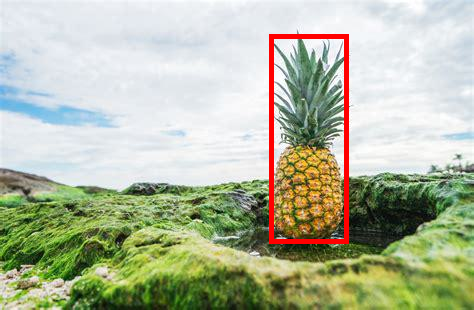

In [21]:
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms import ToPILImage, ToImage

i = 1
img = ToImage()(Image.open(f'./images/pineapple/{i}.jpg').convert('RGB'))
boxes = torch.as_tensor(annotated_boxes[i] * images_hw[i])
result = draw_bounding_boxes(img, boxes, colors=['red']*boxes.shape[0], width=5)
ToPILImage()(result)

### 12.5.4 Masks

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/data_step1.png)

In [ ]:
!wget https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip
!unzip PennFudanPed.zip

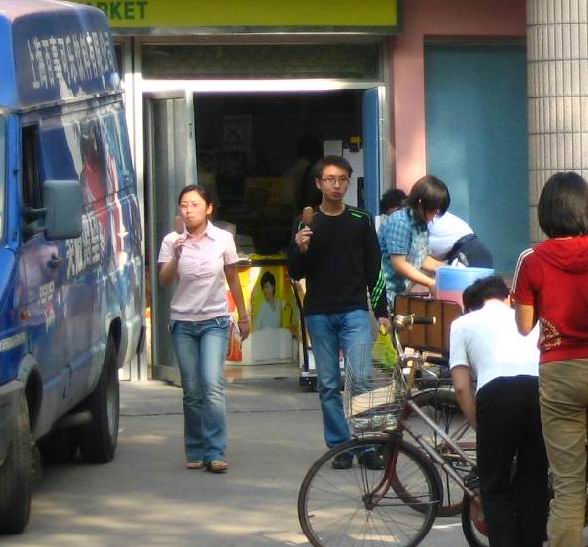

In [23]:
Image.open('PennFudanPed/PNGImages/FudanPed00042.png')

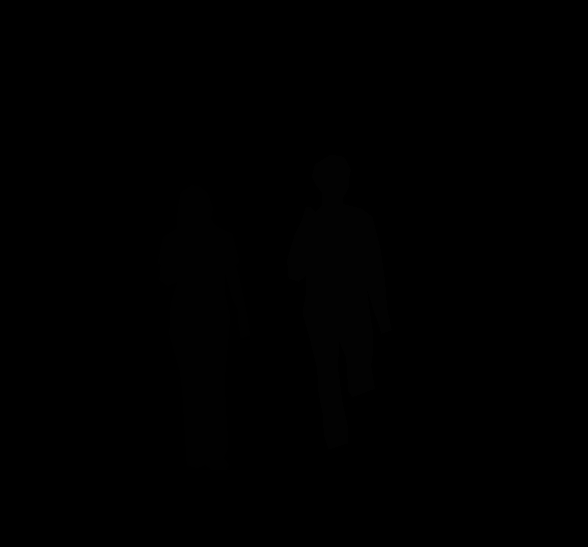

In [24]:
mask_filename = 'PennFudanPed/PedMasks/FudanPed00042_mask.png'
mask_image = Image.open(mask_filename)
mask_image

In [25]:
mask_array = np.array(mask_image)
mask_array

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

In [26]:
np.unique(mask_array)

array([0, 1, 2], dtype=uint8)

In [27]:
colors = [
    0, 0, 0,     # 0 = black
    255, 0, 0,   # 1 = red
    255, 255, 0, # 2 = yellow
]
colors

[0, 0, 0, 255, 0, 0, 255, 255, 0]

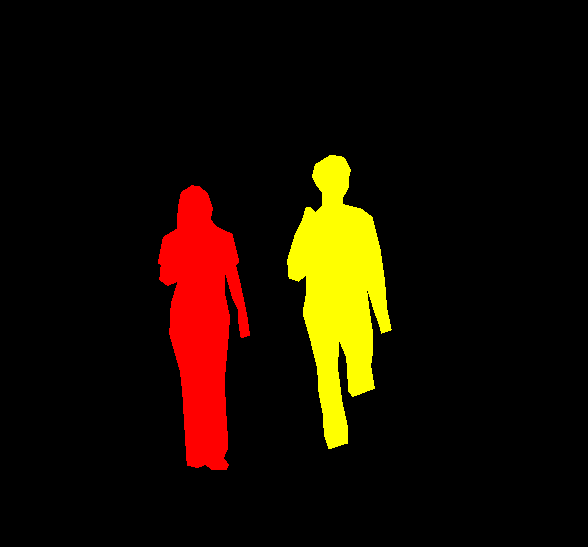

In [28]:
mask_image.putpalette(colors, rawmode='RGB')
mask_image

In [29]:
merged_mask = ToImage()(Image.open(mask_filename).convert('RGB'))
masks = (merged_mask == merged_mask.unique()[1:].view(-1, 1, 1))
masks.shape

torch.Size([2, 547, 588])

In [30]:
from torchvision.ops import masks_to_boxes

boxes = masks_to_boxes(masks)
boxes

tensor([[158., 185., 249., 469.],
        [287., 155., 391., 448.]])

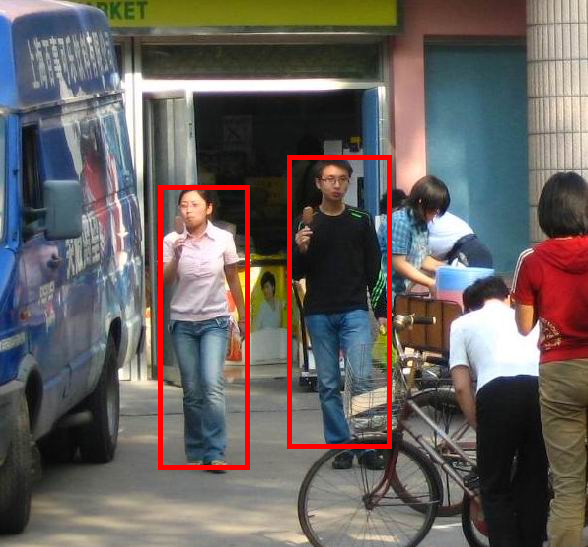

In [31]:
image = ToImage()(Image.open('PennFudanPed/PNGImages/FudanPed00042.png').convert('RGB')
result = draw_bounding_boxes(image, boxes, colors=['red']*boxes.shape[0], width=5)
ToPILImage()(result)

### 12.5.5 Data Augmentation Revisited

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/data_step3.png)

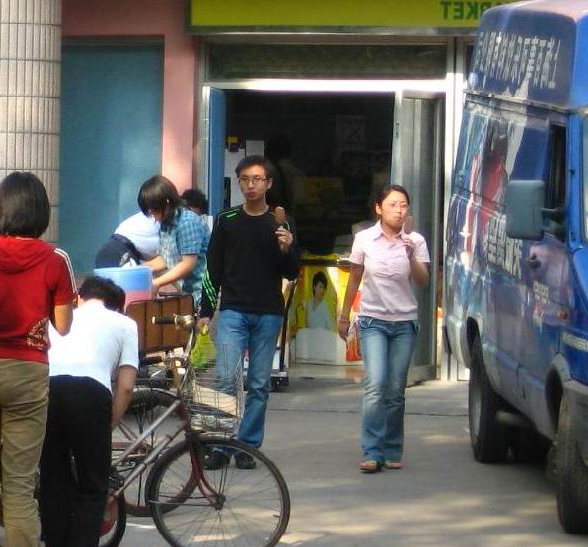

In [32]:
from torchvision.transforms import RandomHorizontalFlip

# forcing the flipping to happen by setting probability to 1.0
flip = RandomHorizontalFlip(p=1.0)
flipped_tensor = flip(image)
ToPILImage()(flipped_tensor)

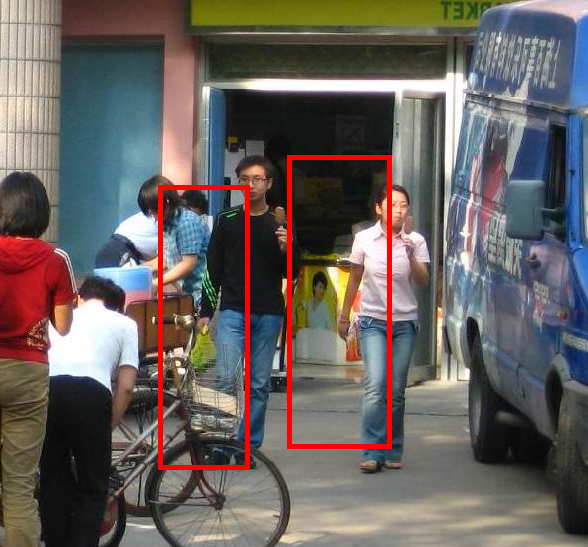

In [33]:
result = draw_bounding_boxes(flipped_tensor, boxes, colors=['red']*boxes.shape[0], width=5)
ToPILImage()(result)

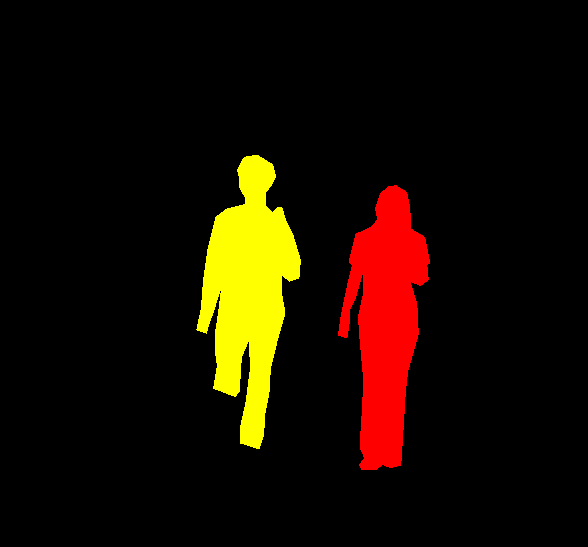

In [34]:
flipped_mask = flip(merged_mask)
flipped_mask_image = ToPILImage()(flipped_mask)
flipped_mask_image.putpalette(colors, rawmode='RGB')
flipped_mask_image

In [35]:
flipped_masks = (flipped_mask == flipped_mask.unique()[1:].view(-1, 1, 1))
flipped_boxes = masks_to_boxes(flipped_masks)
flipped_boxes

tensor([[338., 185., 429., 469.],
        [196., 155., 300., 448.]])

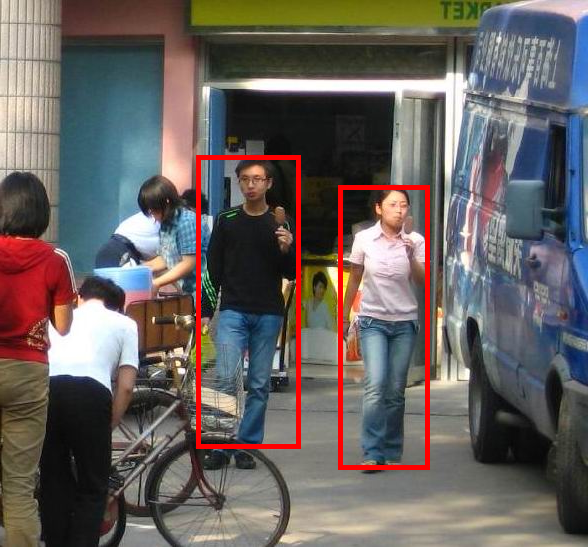

In [36]:
result = draw_bounding_boxes(flipped_tensor, flipped_boxes, colors=['red']*boxes.shape[0], width=5)
ToPILImage()(result)

## 12.6 Transforms (V2)

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/data_step3.png)

In [37]:
import torchvision
# import torchvision.transforms as transforms  # old v1
import torchvision.transforms.v2 as transforms # new v2

from torchvision.transforms.v2 import ToPILImage

In [38]:
flip_v2 = transforms.RandomHorizontalFlip(p=1.0)
flipped_tensor_v2 = flip_v2(image)

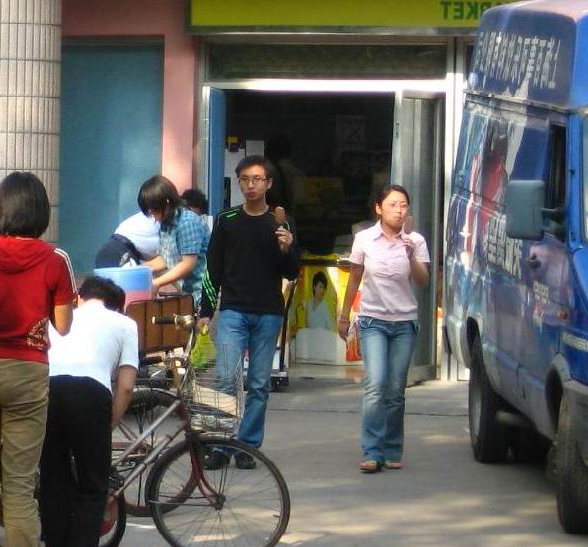

In [39]:
ToPILImage()(flipped_tensor_v2)

In [40]:
flip_v2(boxes)

tensor([[469., 249., 185., 158.],
        [448., 391., 155., 287.]])

In [41]:
flipped_boxes

tensor([[338., 185., 429., 469.],
        [196., 155., 300., 448.]])

In [42]:
from torchvision.tv_tensors import BoundingBoxes, BoundingBoxFormat

pascal_voc = BoundingBoxFormat.XYXY
image_hw = (image.shape[1], image.shape[2])

wrapped_boxes = BoundingBoxes(boxes, format=pascal_voc, canvas_size=image_hw)
wrapped_boxes

BoundingBox([[158., 185., 249., 469.],
             [287., 155., 391., 448.]], format=BoundingBoxFormat.XYXY, spatial_size=(547, 588))

In [43]:
flipped_boxes_v2 = flip_v2(wrapped_boxes)
flipped_boxes_v2

BoundingBox([[339., 185., 430., 469.],
             [197., 155., 301., 448.]], format=BoundingBoxFormat.XYXY, spatial_size=(547, 588))

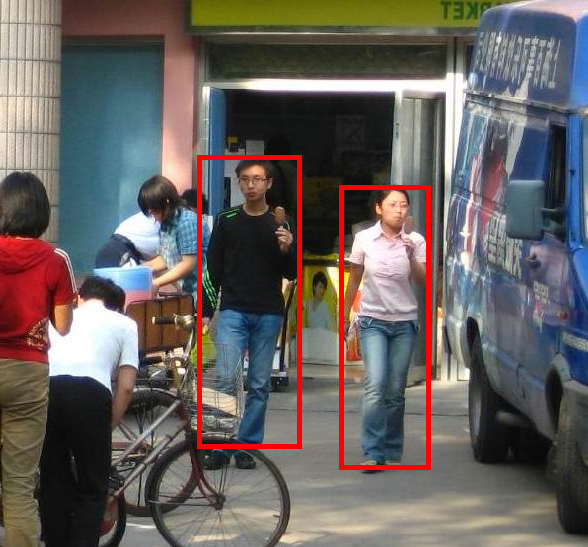

In [44]:
result = draw_bounding_boxes(flipped_tensor_v2, flipped_boxes_v2, colors=['red']*boxes.shape[0], width=5)
ToPILImage()(result)

### 12.6.1 TV_Tensors

In [45]:
image_tensor = ToImage()(Image.open('PennFudanPed/PNGImages/FudanPed00042.png').convert('RGB'))
image_hw = image_tensor.shape[-2:]

mask_filename = 'PennFudanPed/PedMasks/FudanPed00042_mask.png'
merged_mask = ToImage()(Image.open(mask_filename).convert('RGB'))
instances = merged_mask.unique()[1:]

masks = (merged_mask == instances.view(-1, 1, 1))
boxes = masks_to_boxes(masks)

#### 12.6.1.1 Image

In [46]:
from torchvision.tv_tensors import Image

wrapped_image = Image(image_tensor)
wrapped_image

Image([[[216, 214, 211,  ..., 240, 196, 167],
        [221, 220, 218,  ..., 239, 195, 166],
        [226, 225, 224,  ..., 237, 193, 165],
        ...,
        [116, 117, 118,  ..., 102,  97,  92],
        [122, 123, 125,  ...,  96,  83,  74],
        [127, 128, 130,  ...,  86,  68,  57]],

       [[204, 202, 199,  ..., 229, 185, 156],
        [206, 205, 203,  ..., 228, 184, 155],
        [209, 208, 207,  ..., 226, 182, 154],
        ...,
        [116, 117, 119,  ...,  93,  89,  84],
        [122, 123, 126,  ...,  84,  73,  64],
        [127, 128, 131,  ...,  74,  58,  47]],

       [[208, 206, 203,  ..., 211, 167, 138],
        [213, 212, 210,  ..., 210, 166, 137],
        [219, 218, 217,  ..., 208, 164, 136],
        ...,
        [104, 105, 105,  ...,  78,  76,  73],
        [110, 111, 112,  ...,  68,  61,  52],
        [115, 116, 117,  ...,  58,  46,  35]]], dtype=torch.uint8, )

#### 12.6.1.2 BoundingBoxes and BoundingBoxFormat

In [47]:
from torchvision.tv_tensors import BoundingBoxes, BoundingBoxFormat

image_hw = wrapped_image.shape[-2:]
pascal_voc = BoundingBoxFormat.XYXY

wrapped_boxes = BoundingBoxes(boxes, format=pascal_voc, canvas_size=image_hw)
wrapped_boxes

BoundingBox([[158., 185., 249., 469.],
             [287., 155., 391., 448.]], format=BoundingBoxFormat.XYXY, spatial_size=torch.Size([547, 588]))

In [48]:
from torchvision.ops import box_area, box_convert

areas = box_area(wrapped_boxes)
areas

tensor([25844., 30472.])

In [49]:
box_convert(wrapped_boxes, 'xyxy', 'xywh')

tensor([[158., 185.,  91., 284.],
        [287., 155., 104., 293.]])

#### 12.6.1.3 Mask

In [50]:
from torchvision.tv_tensors import Mask

wrapped_masks = Mask(masks)
wrapped_masks

Mask([[[False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False],
       ...,
       [False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False]],

      [[False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False],
       ...,
       [False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False],
       [False, False, False,  ..., False, False, False]]])

#### 12.6.1.4 Video

In [51]:
from torchvision.tv_tensors import Video

### 12.6.2 Transforms

In [52]:
augment_v2 = transforms.Compose([
    transforms.RandomRotation(30),
])

aug_image_v2, aug_boxes_v2, aug_masks_v2 = augment_v2(wrapped_image, wrapped_boxes, wrapped_masks)

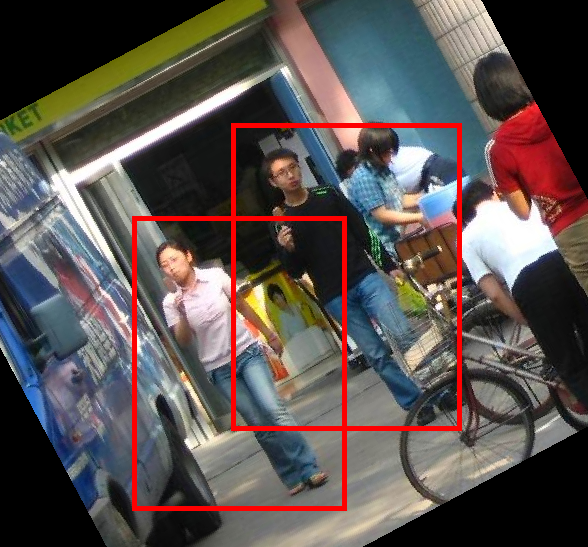

In [53]:
result = draw_bounding_boxes(aug_image_v2, aug_boxes_v2, colors=['red']*aug_boxes_v2.shape[0], width=5)
ToPILImage()(result)

In [54]:
labels = torch.ones((len(instances),), dtype=torch.int64)
targets = {'boxes': wrapped_boxes, 'masks': wrapped_masks, 'labels': labels}

aug_image_v2, aug_targets_v2 = augment_v2(wrapped_image, targets)
aug_targets_v2

{'boxes': BoundingBox([[157.8318, 185.0858, 249.3721, 469.2585],
              [286.7745, 154.8156, 391.3319, 448.0130]], format=BoundingBoxFormat.XYXY, spatial_size=torch.Size([547, 588])),
 'masks': Mask([[[False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        ...,
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False]],
 
       [[False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        ...,
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False]]]),
 'labels': tensor([1, 1])}

#### 12.6.2.1 SanitizeBoundingBox

In [55]:
sanitized_v2 = transforms.Compose([
    transforms.RandomRotation(30),
    transforms.SanitizeBoundingBoxes(),
])
sanitized_image_v2, sanitized_targets_v2 = sanitized_v2(wrapped_image, targets)
sanitized_targets_v2

{'boxes': BoundingBox([[117.7278, 156.8299, 269.9290, 453.9872],
              [248.1572, 156.4353, 415.0417, 465.2716]], format=BoundingBoxFormat.XYXY, spatial_size=torch.Size([547, 588])),
 'masks': Mask([[[False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        ...,
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False]],
 
       [[False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        ...,
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False]]]),
 'labels': tensor([1, 1])}

#### 12.6.2.2 `ToImage()` and `ToDType()`

In [56]:
pil_image = Image.open('PennFudanPed/PNGImages/FudanPed00042.png')

deprecated_t = transforms.ToTensor()
suggested_t = transforms.Compose([transforms.ToImage(), transforms.ToDtype(torch.float32, scale=True)])

torch.allclose(deprecated_t(pil_image), suggested_t(pil_image))

/usr/local/lib/python3.10/dist-packages/torchvision/transforms/v2/_deprecated.py:41: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `transforms.Compose([transforms.ToImageTensor(), transforms.ConvertImageDtype()])`.
  warnings.warn(


True

### 12.6.3 Albumentations

In [57]:
image_tensor = ToImage()(Image.open('PennFudanPed/PNGImages/FudanPed00042.png').convert('RGB'))
image_hw = image_tensor.shape[-2:]

mask_filename = 'PennFudanPed/PedMasks/FudanPed00042_mask.png'
merged_mask = ToImage()(Image.open(mask_filename).convert('RGB'))
instances = merged_mask.unique()[1:]

masks = (merged_mask == instances.view(-1, 1, 1))
boxes = masks_to_boxes(masks)

In [58]:
numpy_image = image_tensor.permute(1, 2, 0).numpy() # from PyTorch's CHW to PIL's HWC format

In [59]:
import albumentations as A
import random
from albumentations.pytorch.transforms import ToTensorV2

transform = A.Compose([
    A.RandomCrop(width=299, height=299),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.2),
    ToTensorV2()
])

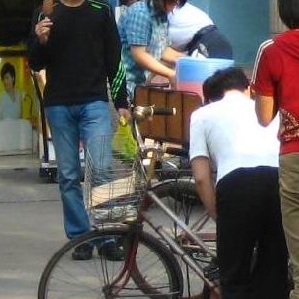

In [60]:
random.seed(34)
transformed = transform(image=numpy_image)
transformed_image = transformed["image"]
ToPILImage()(transformed_image)

In [61]:
transform = A.Compose([
    A.RandomCrop(width=299, height=299),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.2),
    ToTensorV2()
], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['class_labels']))

In [62]:
random.seed(34)
transformed = transform(image=numpy_image, bboxes=boxes, class_labels=[1, 1])
transformed['bboxes'], transformed['class_labels']

([(27.00000110268593, 0.0, 131.00000303983688, 239.0000074505806)], [1])

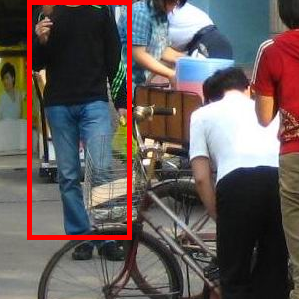

In [63]:
result = draw_bounding_boxes(transformed['image'],
                             torch.as_tensor(transformed['bboxes']),
                             colors=['red']*len(transformed['bboxes']), width=5)
ToPILImage()(result)

## 12.7 Custom Dataset for Object Detection

![](https://raw.githubusercontent.com/dvgodoy/assets/main/PyTorchInPractice/images/ch0/data_step4.png)

Object detection datasets are more complex than image classification datasets. Instead of assigning a single label to an image, we need to associate each image with a variable number of objects and, for every object, information such as its class and bounding box.

In the previous chapters, we introduced Hugging Face Datasets as our primary way of organizing data. We will follow the same approach here instead of creating a custom subclass of PyTorch's Dataset.

Initially, we’ll use images and annotations (or masks) to build framework-neutral representations using a Hugging Face Dataset. Then, we’ll build a function to perform a lazy transformation to a Torchvision-compatible format (image and target) that we can use with a classical object detection model.

This separation is useful because the dataset itself does not need to be tied to a particular model implementation. We can store the annotations in a general format and adapt them later to whatever detector we want to train.

### 12.7.1 Object Detection Records

We will represent each image using a structure commonly used by object detection datasets, like in the example below:
```
{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=588x547>,
 'mask': <PIL.PngImagePlugin.PngImageFile image mode=L size=588x547>,
 'image_id': 41,
 'width': 588,
 'height': 547,
 'objects': {'area': [25844.0, 30472.0],
  'bbox': [[158.0, 185.0, 91.0, 284.0], [287.0, 155.0, 104.0, 293.0]],
  'category': [0, 0],
  'id': [71, 72],
  'iscrowd': [0, 0]}}
```

The objects field contains one entry for each annotated instance in the image. If there are two persons in the image, there are two objects, that is, two bounding boxes and associated information.

The bounding boxes will be stored using the COCO (XYWH) format, where x and y identify the upper-left corner of the box. Notice that this is different from the Pascal (XYXY) representation that we have used with TorchVision. We will convert between these formats later, when preparing the data for a particular model.

There are many ways annotations may originally be stored. Our helper function will support two common cases:
1. a folder containing instance masks;
2. a metadata.jsonl file containing bounding-box annotations.

### 12.7.2 Building Annotation from Instance Masks

In [ ]:
from pathlib import Path
import torch
from torchvision.ops import masks_to_boxes, box_area, box_convert

def _records_from_masks(image_folder, mask_folder, default_category, mask_suffix):
   extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
   image_files = sorted(path for path in image_folder.iterdir() if path.suffix.lower() in extensions)
   # Allows e.g.
   # FudanPed00001.png -> FudanPed00001_mask.png
   mask_files = {path.stem.removesuffix(mask_suffix): path
                 for path in mask_folder.iterdir()
                 if path.suffix.lower() in extensions}

   records = []
   annotation_id = 0

   for image_id, image_path in enumerate(image_files):
       try:
           mask_path = mask_files[image_path.stem]
       except KeyError:
           raise FileNotFoundError(f"No mask found for {image_path.name}")

       merged_mask = ToImage()(Image.open(str(mask_path).convert("L")).squeeze(0)
       height, width = merged_mask.shape
       instance_ids = merged_mask.unique()
       instance_ids = instance_ids[instance_ids != 0]

       if len(instance_ids):
           masks = (merged_mask == instance_ids[:, None, None])
           boxes_xyxy = masks_to_boxes(masks)
           areas = box_area(boxes_xyxy)
           boxes_xywh = box_convert(boxes_xyxy, in_fmt="xyxy", out_fmt="xywh")
           boxes = boxes_xywh.tolist()
           areas = areas.tolist()
       else:
           boxes = []
           areas = []

       n_objects = len(instance_ids)
       object_ids = list(range(annotation_id, annotation_id + n_objects))
       annotation_id += n_objects

       records.append({
           "image": str(image_path),
           # Keep the original merged instance mask available.
           "mask": str(mask_path),
           "image_id": image_id,
           "width": width,
           "height": height,
           "objects": {
               "id": object_ids,
               "bbox": boxes,
               "area": areas,
               "category": [default_category] * n_objects,
               "iscrowd": [0] * n_objects,
           },
       })

   return records

### 12.7.3 Building Annotations from Metadata

In [ ]:
import json
from PIL import Image as PILImage

def _records_from_metadata(image_folder, metadata_file):
   records = []
   next_annotation_id = 0

   with metadata_file.open() as f:
       for image_id, line in enumerate(f):
           if not line.strip():
               continue

           metadata = json.loads(line)
           file_name = metadata.pop("file_name")
           image_path = image_folder / file_name

           if not image_path.exists():
               raise FileNotFoundError(image_path)

           with PILImage.open(image_path) as image:
               width, height = image.size

           objects = dict(metadata.pop("objects"))
           # HF examples have historically used both spellings.
           if "categories" in objects and "category" not in objects:
               objects["category"] = objects.pop("categories")

           boxes = objects.get("bbox", [])
           n_objects = len(boxes)

           if "category" not in objects:
               raise ValueError(f"No categories provided for {file_name}")

           if len(objects["category"]) != n_objects:
               raise ValueError(f"Number of boxes and categories differs for {file_name}")

           # Fill optional COCO-style information if missing.
           if "area" not in objects:
               objects["area"] = [float(w * h) for x, y, w, h in boxes]

           if "id" not in objects:
               objects["id"] = list(range(next_annotation_id, next_annotation_id + n_objects))

           if "iscrowd" not in objects:
               objects["iscrowd"] = [0] * n_objects

           next_annotation_id += n_objects

           records.append({
               "image": str(image_path),
               "image_id": metadata.pop(
                   "image_id",
                   image_id,
               ),
               "width": metadata.pop("width", width),
               "height": metadata.pop("height", height),
               "objects": objects,
               **metadata,   # preserves any additional metadata
           })

   return records

### 12.7.4 Building the Hugging Face Dataset

In [ ]:
from datasets import Dataset, Image as HFImage

def build_object_detection_dataset(image_folder, *, mask_folder, metadata_file=None, default_category=0, mask_suffix="_mask"):
   """
   Builds a Hugging Face object-detection Dataset.

   Exactly one annotation source must be provided:

   mask_folder
       Folder containing instance-ID masks. Pixel value 0 is assumed to
       represent background and each positive value a different instance.

   metadata_file
       Path to a Hugging Face/COCO-style metadata.jsonl file containing
       `file_name` and an `objects` dictionary.

   Bounding boxes in the resulting dataset are stored in COCO XYWH format.
   """

   if (mask_folder is None) == (metadata_file is None):
       raise ValueError("Provide exactly one of mask_folder or metadata_file.")

   image_folder = Path(image_folder)

   if metadata_file is not None:
       records = _records_from_metadata(image_folder, Path(metadata_file))
   else:
       records = _records_from_masks(image_folder, Path(mask_folder), default_category=default_category, mask_suffix=mask_suffix)

   dataset = Dataset.from_list(records)
   dataset = dataset.cast_column("image", HFImage())
   if "mask" in dataset.column_names:
       dataset = dataset.cast_column("mask", HFImage())

   return dataset

### 12.7.5 Penn-Fudan

In [ ]:
penn_ds = build_object_detection_dataset(image_folder='PennFudanPed/PNGImages', mask_folder='PennFudanPed/PedMasks')
len(penn_ds)

In [ ]:
sample = penn_ds[41]
sample

### 12.7.6 Adapting the Dataset to Torchvision

In [ ]:
from torchvision.transforms.functional import pil_to_tensor
from torchvision.tv_tensors import Image, BoundingBoxes, BoundingBoxFormat, Mask
from torchvision.ops import box_convert, box_area

def build_detection_transform(transforms=None):
   def transform_fn(examples):
       images = []
       targets = []

       base = {'image': None, 'mask': None, 'image_id': None, 'objects': None}
       base.update(**examples)

       for (image, merged_mask, image_id, objects) in zip(base["image"], base["mask"], base["image_id"], base["objects"]):
           image = Image(pil_to_tensor(image.convert("RGB")))
           height, width = image.shape[-2:]

           # HF stores COCO XYWH
           boxes = torch.tensor(objects["bbox"], dtype=torch.float32).reshape(-1, 4)
           boxes = box_convert(boxes, in_fmt="xywh", out_fmt="xyxy")
           boxes = BoundingBoxes(boxes, format=BoundingBoxFormat.XYXY, canvas_size=(height, width))

           if merged_mask is not None:
               # Recreate individual masks from Penn-Fudan's merged mask
               merged_mask = pil_to_tensor(merged_mask).squeeze(0)
               instance_ids = merged_mask.unique()
               instance_ids = instance_ids[instance_ids != 0]
               masks = Mask(merged_mask == instance_ids[:, None, None])
           else:
               masks = None

           # HF category 0 = pedestrian.
           # TorchVision detectors reserve 0 for background.
           labels = torch.tensor(objects["category"], dtype=torch.int64,) + 1

           target = {
               "boxes": boxes,
               "labels": labels,
               "masks": masks,
               "image_id": torch.tensor(image_id),
               "iscrowd": torch.tensor(objects["iscrowd"], dtype=torch.int64)
           }

           if transforms is not None:
               image, target = transforms(image, target)

           # Compute this AFTER geometric augmentation
           target["area"] = box_area(target["boxes"])

           images.append(image)
           targets.append(target)

       return {"image": images, "target": targets}

   return transform_fn

### 12.7.7 Lazy Transformations

In [ ]:
penn_ds = penn_ds.with_transform(build_detection_transform())
sample = penn_ds[41]

image = sample["image"]
targets = sample["target"]
targets

### 12.7.8 Checking the Bounding Boxes

In [ ]:
result = draw_bounding_boxes(image, targets['boxes'], colors=['red']*len(targets['boxes']), width=5)
ToPILImage()(result)

### 12.7.9 Batching Object Detection Data

In [ ]:
def collate_fn(batch):
   images = [item["image"] for item in batch]
   targets = [item["objects"] for item in batch]

   return images, targets

In [ ]:
from torch.utils.data import DataLoader

loader = DataLoader(penn_ds, batch_size=4, shuffle=True, collate_fn=collate_fn)
next(iter(loader))